# Patient 30-Day Readmission Risk Prediction

**Goal.** Estimate the probability that a diabetic patient is readmitted within 30 days of discharge, so follow-up care can be prioritised.

**Data.** [Diabetes 130-US Hospitals (1999–2008)](https://www.openml.org/d/43874), OpenML version: about 101.8K encounters, target `readmit_30_days` (about 11% positive).

**Design principles**
1. Split first. Everything *learned* from data (clipping cap, encoders, scaler, model, calibrator) lives inside a scikit-learn `Pipeline` and is fit on training data only.
2. Models are compared with 5-fold cross-validation on the training set. The test set is used once, for the final model.
3. The saved artifact is a single object that accepts cleaned raw columns, so the Streamlit app cannot drift from the notebook.

**Notebook map**

| # | Section | Output |
|---|---------|--------|
| 1 | Setup | imports, constants |
| 2 | Load data | raw DataFrame |
| 3 | Data understanding | target rate, hidden missing values |
| 4 | Cleaning | deterministic cleaning, leakage columns removed |
| 5 | Splitting | train / validation / test |
| 6 | Feature engineering | `FeatureBuilder` + preprocessing |
| 7 | Model comparison | 5-fold CV on train |
| 8 | Imbalance experiment | SMOTE vs class weights vs nothing (same model) |
| 9 | Calibration and threshold | isotonic calibration, threshold on validation |
| 10 | Test evaluation | metrics, bootstrap CI, reliability plot |
| 11 | Feature importance | permutation importance |
| 12 | Save artifact | `models/readmission_model.joblib` |

> Requires `features.py` in the same folder (shared with the Streamlit app).

## 1. Setup

In [2]:
import json
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))  # make features.py importable here...
os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")  # ...and in CV worker processes

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import fetch_openml
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

from features import (
    BINARY_COLS,
    CATEGORICAL_COLS,
    ENGINEERED_NUMERIC_COLS,
    HIDDEN_MISSING,
    RAW_NUMERIC_COLS,
    TARGET,
    FeatureBuilder,
    build_preprocessor,
    clean_raw,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

SEED = 42
TARGET_RECALL = 0.60  # operating point: catch at least 60% of future readmissions
MODEL_PATH = Path("models/readmission_model.joblib")
Path("assets").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


## 2. Load data

In [3]:
raw = fetch_openml(data_id=43874, as_frame=True, parser="auto").frame
print("Rows x columns:", raw.shape)
raw.head()

Rows x columns: (101766, 25)


,race,gender,age,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,change,diabetesMed,medicare,medicaid,had_emergency,had_inpatient_days,had_outpatient_days,readmitted,readmit_binary,readmit_30_days
0,Caucasian,Female,'30 years or younger',Other,Referral,1,Other,41,0,1,...,No,No,False,False,False,False,False,NO,0,0
1,Caucasian,Female,'30 years or younger','Discharged to Home',Emergency,3,Missing,59,0,18,...,Ch,Yes,False,False,False,False,False,>30,1,0
2,AfricanAmerican,Female,'30 years or younger','Discharged to Home',Emergency,2,Missing,11,5,13,...,No,Yes,False,False,False,True,True,NO,0,0
3,Caucasian,Male,'30-60 years','Discharged to Home',Emergency,2,Missing,44,1,16,...,Ch,Yes,False,False,False,False,False,NO,0,0
4,Caucasian,Male,'30-60 years','Discharged to Home',Emergency,1,Missing,51,0,8,...,Ch,Yes,False,False,False,False,False,NO,0,0


## 3. Data understanding

Missing values in this dataset are not `NaN`. They are hidden behind placeholder strings (`?`, `Unknown`, `Missing`, `None`, `Unknown/Invalid`), so `df.isnull()` reports nothing. Count them explicitly.

In [4]:
print(f"Positive rate ({TARGET}): {raw[TARGET].mean():.2%}")

text_cols = raw.select_dtypes(exclude=["number", "bool"]).columns
hidden_counts = {
    col: int(raw[col].astype(str).str.strip("'").isin(HIDDEN_MISSING).sum()) for col in text_cols
}
pd.Series(hidden_counts).loc[lambda s: s > 0].sort_values(ascending=False).rename("hidden-missing count")

Positive rate (readmit_30_days): 11.16%


,hidden-missing count
max_glu_serum,96420
A1Cresult,84748
medical_specialty,49949
race,2273
gender,3


## 4. Cleaning

All steps are deterministic (nothing is learned from the data), so they are safe to apply before splitting. The logic lives in `features.clean_raw` so the app reuses it.

| Step | Reason |
|------|--------|
| Drop `readmitted`, `readmit_binary` | Alternative encodings of the target (leakage) |
| Strip literal quotes from labels (`'Over 60 years'`) | Clean category names |
| Drop 3 rows with invalid gender | Negligible loss |
| `race`, `medical_specialty` missing → `Unknown` | Genuinely unknown |
| `max_glu_serum`, `A1Cresult` missing → `Not Tested` | The test was not ordered, which is itself a signal |
| Yes/No/Ch/True/False → 1/0 | Binary flags |

In [5]:
df = clean_raw(raw)
print(f"{raw.shape} -> {df.shape}")
assert df.isna().sum().sum() == 0, "unexpected missing values after cleaning"
df[BINARY_COLS].head()

(101766, 25) -> (101763, 23)


,change,diabetesMed,medicare,medicaid,had_emergency,had_inpatient_days,had_outpatient_days
0,0,0,0,0,0,0,0
1,1,1,0,0,0,0,0
2,0,1,0,0,0,1,1
3,1,1,0,0,0,0,0
4,1,1,0,0,0,0,0


## 5. Splitting

Three disjoint sets with different jobs:

- **Train** (80%): model selection via cross-validation.
- **Fit / Validation** (an 80/20 split *inside* train): fit and calibrate the final model on *fit*, choose the decision threshold on *validation*.
- **Test** (20%): touched once, at the end.

> The OpenML version has no patient ID, so several encounters of one patient can land in different splits. Reported scores may therefore be slightly optimistic.

In [6]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED
)

for name, part in [("train", y_train), ("  fit", y_fit), ("  val", y_val), ("test", y_test)]:
    print(f"{name}: {len(part):>6,} rows, positive rate {part.mean():.3f}")

train: 81,410 rows, positive rate 0.112
  fit: 65,128 rows, positive rate 0.112
  val: 16,282 rows, positive rate 0.112
test: 20,353 rows, positive rate 0.112


## 6. Feature engineering

`FeatureBuilder` is fit on training data only (the clipping cap is learned there), then a `ColumnTransformer` scales numerics and one-hot encodes categoricals.

| Feature | Definition | Rationale |
|---------|-----------|-----------|
| `time_in_hospital` | clipped at the train 99th percentile | limit outlier influence |
| `num_medications_log` | `log1p(num_medications)` | reduce right skew |
| `time_x_meds` | length of stay × number of medications | interaction: long stays with heavy medication |
| `total_procedures` | lab procedures + procedures | one procedure-load measure |
| `care_intensity` | total procedures + medications + diagnoses | overall care burden |
| `had_emergency`, `had_inpatient_days`, `had_outpatient_days` | kept as three separate flags | the previous notebook summed them, which hides *which* kind of earlier visit matters |

The pairs below are the highly correlated engineered numerics. The final model is tree-based, so this does not hurt it, and logistic regression is L2-regularised by default.

In [7]:
fb = FeatureBuilder().fit(X_train)
engineered = fb.transform(X_train)
print(f"Clipping cap for time_in_hospital (train p99): {fb.time_cap_:.0f} days")

corr = engineered[ENGINEERED_NUMERIC_COLS].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs[pairs > 0.8].sort_values(ascending=False).rename("|correlation| > 0.8")

Clipping cap for time_in_hospital (train p99): 14 days


,,|correlation| > 0.8
total_procedures,care_intensity,0.937298
time_in_hospital,time_x_meds,0.838053


In [8]:
def make_pipeline(model):
    """features -> preprocessing -> model, all fit on whatever data fit() receives."""
    return Pipeline(
        [("features", FeatureBuilder()), ("prep", build_preprocessor()), ("model", model)]
    )

## 7. Model comparison (5-fold CV on the training set)

Class imbalance (about 11% positives) is handled with `class_weight="balanced"` here. ROC-AUC measures ranking quality. PR-AUC is also reported because it is more informative under imbalance (a random model scores about the positive rate, ≈ 0.11).

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}


def cv_table(estimators):
    rows = []
    for name, estimator in estimators.items():
        res = cross_validate(estimator, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
        rows.append(
            {
                "model": name,
                "ROC-AUC": f"{res['test_roc_auc'].mean():.3f} ± {res['test_roc_auc'].std():.3f}",
                "PR-AUC": f"{res['test_pr_auc'].mean():.3f} ± {res['test_pr_auc'].std():.3f}",
            }
        )
    return pd.DataFrame(rows).set_index("model")


candidates = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=2000)
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=20,
            class_weight="balanced_subsample",
            n_jobs=1,
            random_state=SEED,
        )
    ),
    "HistGradientBoosting": make_pipeline(
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)
    ),
}
cv_table(candidates)

,ROC-AUC,PR-AUC
model,,
Logistic Regression,0.634 ± 0.003,0.164 ± 0.001
Random Forest,0.640 ± 0.005,0.173 ± 0.002
HistGradientBoosting,0.637 ± 0.004,0.171 ± 0.002


**Reading the table.** All three models land within about 0.006 ROC-AUC of each other (0.634–0.640), and the gap between Random Forest and HistGradientBoosting (0.003) is inside the fold-to-fold spread. Logistic regression is almost as good as the tree models, which suggests the usable signal in these features is mostly simple and additive, and that model choice is not the bottleneck here.

Because raw score does not separate the candidates, **HistGradientBoosting is chosen on secondary grounds**: it trains quickly, needs little tuning, and works well with isotonic calibration (checked in the reliability plot in section 10). The scores above use `class_weight="balanced"`, which distorts predicted probabilities, so the final model drops it and relies on calibration instead.

## 8. Imbalance experiment: SMOTE vs class weights vs nothing

A fair test changes **one thing**: the imbalance strategy. Same model (Random Forest), same hyperparameters, same folds. SMOTE sits *inside* the pipeline, so it only ever sees the training folds and the validation fold stays untouched.

> Plain SMOTE interpolates one-hot columns as if they were continuous. `SMOTENC` would respect them. This is a known limitation of the experiment.

In [10]:
rf_params = dict(n_estimators=300, min_samples_leaf=20, n_jobs=1, random_state=SEED)

imbalance_experiment = {
    "RF, no imbalance handling": make_pipeline(RandomForestClassifier(**rf_params)),
    "RF + class_weight": make_pipeline(
        RandomForestClassifier(class_weight="balanced_subsample", **rf_params)
    ),
    "RF + SMOTE": ImbPipeline(
        [
            ("features", FeatureBuilder()),
            ("prep", build_preprocessor()),
            ("smote", SMOTE(random_state=SEED)),
            ("model", RandomForestClassifier(**rf_params)),
        ]
    ),
}
cv_table(imbalance_experiment)  # SMOTE row takes a few minutes

,ROC-AUC,PR-AUC
model,,
"RF, no imbalance handling",0.639 ± 0.005,0.174 ± 0.004
RF + class_weight,0.640 ± 0.005,0.173 ± 0.002
RF + SMOTE,0.627 ± 0.003,0.165 ± 0.002


**Reading the table.** Doing nothing (0.639) and using class weights (0.640) are indistinguishable: the gap is far smaller than the fold-to-fold spread. SMOTE is the only change that moves the score, and it moves it down: about 0.012 lower ROC-AUC (0.627) and about 0.009 lower PR-AUC (0.165 vs 0.173–0.174), both larger than the spread across folds.

So, with the model and hyperparameters held fixed, SMOTE does not help on this dataset, and rebalancing the classes is not needed for ranking quality at all. The final model therefore uses **no resampling and no class weights**, which also keeps its predicted probabilities realistic before calibration. Caveat: plain SMOTE treats one-hot columns as continuous, so a categorical-aware variant (`SMOTENC`) might behave differently. This result applies to this setup, not to SMOTE in general.

## 9. Calibration and threshold selection

**Final model:** HistGradientBoosting without `class_weight`. Re-weighting classes distorts predicted probabilities. Without it, plus isotonic calibration, a prediction of 0.15 can be read as "about 15% risk".

- Fit and calibrate on the **fit** set (`CalibratedClassifierCV` with internal 5-fold cross-fitting).
- Pick the **threshold** on the **validation** set: the highest threshold that still reaches the target recall.

In [11]:
raw_model = make_pipeline(HistGradientBoostingClassifier(random_state=SEED)).fit(X_fit, y_fit)  # uncalibrated reference

final_model = CalibratedClassifierCV(
    make_pipeline(HistGradientBoostingClassifier(random_state=SEED)),
    method="isotonic",
    cv=5,
).fit(X_fit, y_fit)

p_val = final_model.predict_proba(X_val)[:, 1]
precision_v, recall_v, thresholds_v = precision_recall_curve(y_val, p_val)
idx = np.where(recall_v[:-1] >= TARGET_RECALL)[0][-1]
threshold = float(thresholds_v[idx])
print(f"Threshold chosen on validation for recall >= {TARGET_RECALL:.0%}: {threshold:.3f}")

Threshold chosen on validation for recall >= 60%: 0.120


## 10. Test-set evaluation (used once)

In [12]:
p_test = final_model.predict_proba(X_test)[:, 1]
p_test_uncal = raw_model.predict_proba(X_test)[:, 1]
y_true = y_test.to_numpy()
base_rate = float(y_train.mean())

pred = (p_test >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
precision = tp / (tp + fp)

metrics = {
    "roc_auc": roc_auc_score(y_true, p_test),
    "pr_auc": average_precision_score(y_true, p_test),
    "brier": brier_score_loss(y_true, p_test),
    "brier_uncalibrated": brier_score_loss(y_true, p_test_uncal),
    "brier_base_rate_only": brier_score_loss(y_true, np.full(len(y_true), base_rate)),
    "threshold": threshold,
    "recall": tp / (tp + fn),
    "precision": precision,
    "lift_vs_base_rate": precision / y_true.mean(),
    "flagged_share": (tp + fp) / len(y_true),
    "test_positive_rate": float(y_true.mean()),
    "mean_predicted_probability": float(p_test.mean()),
}


def bootstrap_ci(metric, y_arr, p_arr, n_boot=500, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_arr)
    values = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        values.append(metric(y_arr[i], p_arr[i]))
    return np.percentile(values, [2.5, 97.5])


ci_roc = bootstrap_ci(roc_auc_score, y_true, p_test)
ci_pr = bootstrap_ci(average_precision_score, y_true, p_test)

print(f"ROC-AUC : {metrics['roc_auc']:.3f}  (95% CI {ci_roc[0]:.3f}-{ci_roc[1]:.3f})")
print(f"PR-AUC  : {metrics['pr_auc']:.3f}  (95% CI {ci_pr[0]:.3f}-{ci_pr[1]:.3f})  [baseline = {metrics['test_positive_rate']:.3f}]")
print(f"Brier   : {metrics['brier']:.4f} calibrated | {metrics['brier_uncalibrated']:.4f} uncalibrated | {metrics['brier_base_rate_only']:.4f} base-rate only")
print(f"At threshold {threshold:.3f}: recall {metrics['recall']:.3f}, precision {metrics['precision']:.3f} "
      f"({metrics['lift_vs_base_rate']:.2f}x base rate), flags {metrics['flagged_share']:.1%} of patients")
print(f"Mean predicted probability {metrics['mean_predicted_probability']:.3f} vs observed rate {metrics['test_positive_rate']:.3f}")

ROC-AUC : 0.651  (95% CI 0.640-0.662)
PR-AUC  : 0.183  (95% CI 0.172-0.196)  [baseline = 0.112]
Brier   : 0.0963 calibrated | 0.0964 uncalibrated | 0.0991 base-rate only
At threshold 0.120: recall 0.606, precision 0.165 (1.48x base rate), flags 40.9% of patients
Mean predicted probability 0.112 vs observed rate 0.112


**Reliability plot.** A calibrated model's points sit on the diagonal: when it says 20%, about 20% of those patients are actually readmitted. Averages matching (above) is necessary but not sufficient, so check it bin by bin.

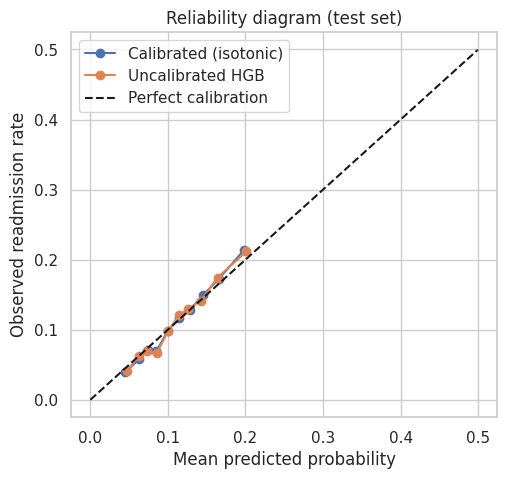

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, probs in [("Calibrated (isotonic)", p_test), ("Uncalibrated HGB", p_test_uncal)]:
    frac_pos, mean_pred = calibration_curve(y_true, probs, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=label)
upper = max(p_test.max(), p_test_uncal.max())
ax.plot([0, upper], [0, upper], "k--", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed readmission rate")
ax.set_title("Reliability diagram (test set)")
ax.legend()
fig.savefig("assets/calibration.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the results.** On the untouched test set the model reaches ROC-AUC 0.651 (95% CI 0.640–0.662) and PR-AUC 0.183 (95% CI 0.172–0.196) against a base rate of 0.112, so it ranks patients better than chance, but only modestly. At the validation-chosen threshold (0.120) it catches 60.6% of readmissions while flagging 40.9% of patients; precision is 16.5%, about 1.5× the base rate. Mean predicted risk matches the observed rate (0.112) and the reliability curve follows the diagonal. Isotonic calibration barely changes the Brier score (0.0963 vs 0.0964 uncalibrated), so gradient boosting without class weights was already close to calibrated; calibration here is a verified safeguard, not a source of accuracy.

## 11. Feature importance

Permutation importance on the **validation** set (so the test set stays untouched), computed on the *original input columns*: shuffle one column and measure the drop in ROC-AUC. Because the model is a full pipeline, the result maps directly to the inputs a user types into the app. Correlated inputs share credit, so treat small differences between neighbours with caution.

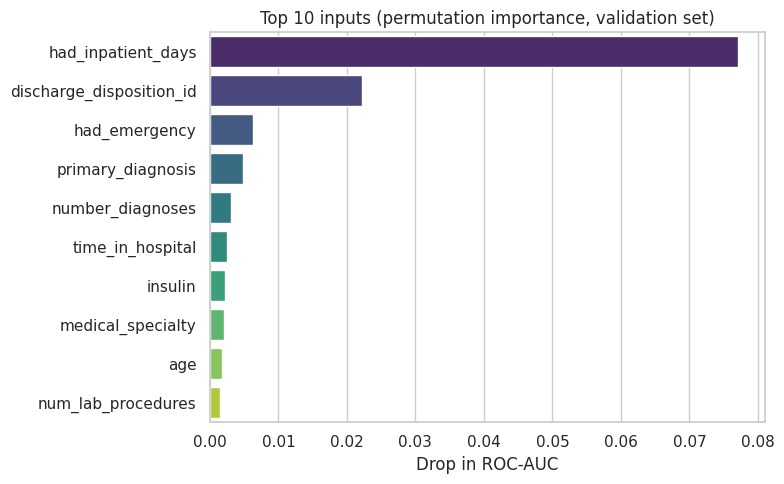

,feature,drop_in_roc_auc,std
0,had_inpatient_days,0.077129,0.006404
1,discharge_disposition_id,0.022234,0.000924
2,had_emergency,0.006322,0.001381
3,primary_diagnosis,0.004846,0.000923
4,number_diagnoses,0.003010,0.000854
5,time_in_hospital,0.002552,0.000967
6,insulin,0.002136,0.001166
7,medical_specialty,0.002085,0.000279
8,age,0.001736,0.000441
9,num_lab_procedures,0.001519,0.001009


In [14]:
result = permutation_importance(
    final_model, X_val, y_val, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1
)
importance = (
    pd.DataFrame(
        {
            "feature": X_val.columns,
            "drop_in_roc_auc": result.importances_mean,
            "std": result.importances_std,
        }
    )
    .sort_values("drop_in_roc_auc", ascending=False)
    .reset_index(drop=True)
)

top10 = importance.head(10)
plt.figure(figsize=(8, 5))
sns.barplot(data=top10, x="drop_in_roc_auc", y="feature", hue="feature", palette="viridis", legend=False)
plt.title("Top 10 inputs (permutation importance, validation set)")
plt.xlabel("Drop in ROC-AUC")
plt.ylabel("")
plt.tight_layout()
plt.savefig("assets/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
top10

**Reading the importances.** A prior inpatient stay (`had_inpatient_days`) dominates: shuffling it costs about 0.077 ROC-AUC, several times any other input. Non-home discharge disposition is second (about 0.022), and every remaining input contributes less than 0.01. Importance shows what the model relies on, not what causes readmission.

## 12. Save artifact for the app

One file holds everything the app needs: the full pipeline (feature engineering + encoding + scaling + model + calibrator), the threshold, dropdown choices, slider ranges, per-input defaults and the headline metrics. Defaults are taken from the training data, in the original units, so the app no longer needs "median after scaling" tricks.

In [15]:
choices = {col: sorted(X_train[col].unique().tolist()) for col in CATEGORICAL_COLS}
ranges = {col: (int(X_train[col].min()), int(X_train[col].max())) for col in RAW_NUMERIC_COLS}
defaults = {col: int(X_train[col].median()) for col in RAW_NUMERIC_COLS}
defaults.update({col: int(X_train[col].mode().iloc[0]) for col in BINARY_COLS})
defaults.update({col: str(X_train[col].mode().iloc[0]) for col in CATEGORICAL_COLS})

metrics_out = {k: round(float(v), 4) for k, v in metrics.items()}
metrics_out["roc_auc_ci95"] = [round(float(v), 4) for v in ci_roc]
metrics_out["pr_auc_ci95"] = [round(float(v), 4) for v in ci_pr]
metrics_out["target_recall"] = TARGET_RECALL

bundle = {
    "model": final_model,
    "threshold": threshold,
    "base_rate": base_rate,
    "feature_columns": list(X_train.columns),
    "defaults": defaults,
    "choices": choices,
    "ranges": ranges,
    "metrics": metrics_out,
    "top_features": top10[["feature", "drop_in_roc_auc"]].round(4).to_dict("records"),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, MODEL_PATH, compress=3)
Path("assets/metrics.json").write_text(json.dumps(metrics_out, indent=2))
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("Pin in requirements.txt: scikit-learn==" + sklearn.__version__)

Saved models/readmission_model.joblib (0.4 MB)
Pin in requirements.txt: scikit-learn==1.6.1


**Round-trip check.** Reload the artifact and confirm it reproduces the notebook's predictions exactly. This guards against train/serve skew. Then score one app-style row built purely from the stored defaults.

In [16]:
loaded = joblib.load(MODEL_PATH)
reloaded = loaded["model"].predict_proba(X_test.iloc[:200])[:, 1]
assert np.allclose(reloaded, p_test[:200]), "reloaded model disagrees with notebook"

row = pd.DataFrame([loaded["defaults"]])[loaded["feature_columns"]]
prob = loaded["model"].predict_proba(row)[0, 1]
print(f"Default (typical) patient: {prob:.1%} predicted risk | flagged: {prob >= loaded['threshold']}")

Default (typical) patient: 7.9% predicted risk | flagged: False


## Limitations

- Moderate discriminative power (ROC-AUC near 0.65) is typical for this problem; the model supports screening and prioritisation, not individual clinical decisions.
- At the chosen operating point about 41% of patients are flagged, with precision about 1.5× the base rate (see `flagged_share`), so precision is only modestly above the base rate.
- No patient ID in this version of the data, so splits could not be grouped by patient.
- Discharge disposition is pre-grouped into "Home" and "Other", so expired and hospice encounters (excluded in the original study) cannot be removed.
- Data covers US hospitals from 1999 to 2008; practice patterns have changed.
- Educational project, not intended for clinical use.